# DBSCAN Clustering with Scikit-learn

**Real dataset:** Old Faithful Geyser (272 recorded eruptions)  
**Features:** `eruptions` (eruption duration, minutes) and `waiting` (waiting time, minutes)

**Objective:** Find clusters and noise using DBSCAN, then evaluate the clusters with the **Silhouette Score**.

> Keep `old_faithful.csv` in the same folder as this notebook. Dataset source: [R `faithful` dataset](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/faithful.html).

## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

## 2. Load the dataset

Each row represents one geyser eruption.

In [ ]:
df = pd.read_csv("old_faithful.csv")

display(df.head())

df.isna().sum().to_frame("Missing values")

,eruptions,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


,Missing values
eruptions,0
waiting,0


## 3. Visualize the original data

We use a scatter plot because this dataset has **two numerical features**.

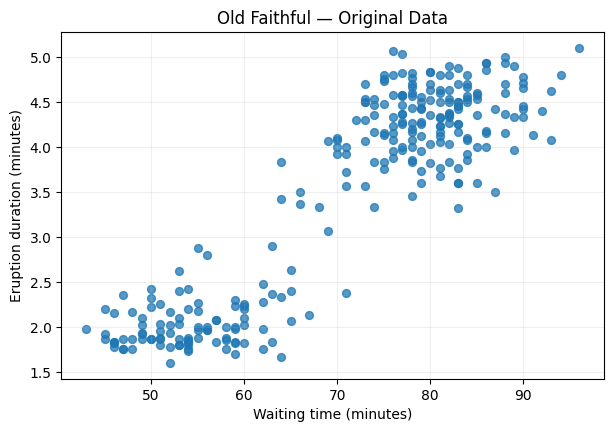

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.scatter(df["waiting"], df["eruptions"], s=32, alpha=0.75)
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Eruption duration (minutes)")
plt.title("Old Faithful — Original Data")
plt.grid(alpha=0.2)
plt.show()

## 4. Scale the features

DBSCAN uses **distance**. `waiting` and `eruptions` have different scales, so we standardize both columns before clustering.

In [ ]:
X = df[["eruptions", "waiting"]]
X_scaled = StandardScaler().fit_transform(X)

pd.DataFrame(X_scaled, columns=X.columns).head()

,eruptions,waiting
0,0.098499,0.597123
1,-1.481459,-1.245181
2,-0.135861,0.228663
3,-1.057503,-0.655644
4,0.917443,1.039277


## 5. Apply DBSCAN

- `eps=0.30` is the neighborhood radius **in scaled feature units**.
- `min_samples=5` is the minimum number of points in a core point's neighborhood, including itself.
- Cluster labels are `0, 1, ...`; label `-1` means **noise**.

In [ ]:
dbscan = DBSCAN(eps=0.30, min_samples=5)
labels = dbscan.fit_predict(X_scaled)
df["cluster"] = labels

df["cluster"].value_counts().sort_index().to_frame("Number of points")

,Number of points
cluster,
-1,8
0,168
1,96


## 6. Visualize the clusters

DBSCAN assigns a cluster label to dense groups. **X markers** show noise points. We plot the original values in minutes so the graph is easier to interpret.

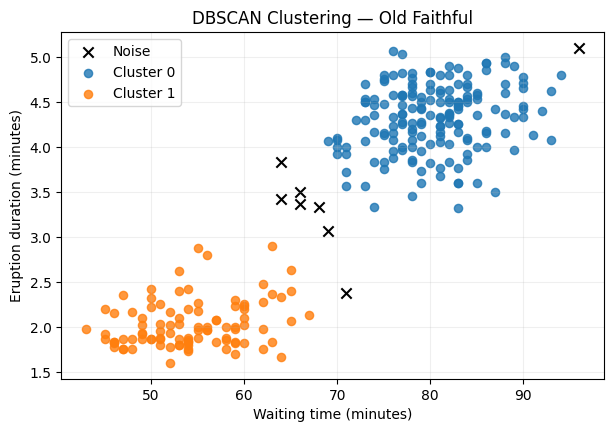

In [ ]:
plt.figure(figsize=(7, 4.5))

for cluster_id in sorted(df["cluster"].unique()):
    points = df[df["cluster"] == cluster_id]

    if cluster_id == -1:
        plt.scatter(points["waiting"], points["eruptions"],
                    c="black", marker="x", s=55, label="Noise")
    else:
        plt.scatter(points["waiting"], points["eruptions"],
                    s=35, alpha=0.8, label=f"Cluster {cluster_id}")

plt.xlabel("Waiting time (minutes)")
plt.ylabel("Eruption duration (minutes)")
plt.title("DBSCAN Clustering — Old Faithful")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 7. Evaluate with the Silhouette Score

The **Silhouette Score** measures how well clusters are separated:

- **Near +1:** well-separated clusters
- **Near 0:** overlapping clusters
- **Below 0:** some points may be in an unsuitable cluster

We **exclude noise** (`-1`) from this score. A score requires at least two clusters and at least one more point than the number of clusters.

In [ ]:
keep = labels != -1
cluster_labels = labels[keep]

if 2 <= len(set(cluster_labels)) < len(cluster_labels):
    score = silhouette_score(X_scaled[keep], cluster_labels)
    result = pd.DataFrame({"Silhouette Score": [round(score, 3)]})
else:
    result = "Silhouette Score requires at least 2 valid clusters."

result

,Silhouette Score
0,0.771


## 8. Core, border, and noise points

- **Core:** has enough nearby points to form a dense region.
- **Border:** belongs to a cluster but is not a core point.
- **Noise:** does not belong to any cluster.

In [ ]:
point_type = np.full(len(df), "Border", dtype=object)
point_type[labels == -1] = "Noise"
point_type[dbscan.core_sample_indices_] = "Core"

df["point_type"] = point_type

display(df["point_type"].value_counts().to_frame("Number of points"))
df.head()

,Number of points
point_type,
Core,252
Border,12
Noise,8


,eruptions,waiting,cluster,point_type
0,3.600,79,0,Core
1,1.800,54,1,Core
2,3.333,74,0,Border
3,2.283,62,1,Core
4,4.533,85,0,Core


## Conclusion

DBSCAN finds dense groups **without specifying the number of clusters beforehand**. It also identifies noise points (label `-1`). We use the Silhouette Score to evaluate cluster separation, but we should also inspect the scatter plot.

**Try it yourself:** Change `eps` to `0.20` or `0.35`, rerun the DBSCAN steps, and observe how the number of noise points and Silhouette Score change.